In [ ]:
# Learn Specific data science libraries like 
##    Pandas, 
##    Scikit-learn, 
##    Numpy, 
##    Scatterplots, 
##    Box plots, 
##    Statistical measuresfor 
# outlier Detection using a Python Data Science Program

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

In [3]:
# ==========================================
# 1. SAMPLE DATASET CREATION (12 Rows)
# ==========================================
# Features represent clinical cell measurements (similar to medical datasets)
data = {
    "cell_size": [1.2, 1.5, 1.8, 1.1, 1.3, 2.0, 8.5, 9.1, 8.8, 9.5, 1.4, 25.0],
    "cell_shape": [1.0, 1.2, 1.5, 1.1, 1.4, 1.8, 7.8, 8.9, 8.2, 9.0, 1.3, 30.0],
    "adhesion": [1.1, 1.3, 1.2, 1.0, 1.5, 1.7, 6.5, 7.2, 6.8, 8.1, 1.1, 28.0],
    "label": [
        "Benign",
        "Benign",
        "Benign",
        "Benign",
        "Benign",
        "Benign",
        "Malignant",
        "Malignant",
        "Malignant",
        "Malignant",
        "Benign",
        "Malignant",
    ],
}

df = pd.DataFrame(data)
print("--- Raw Dataset (First 12 Rows) ---")
print(df)

--- Raw Dataset (First 12 Rows) ---
    cell_size  cell_shape  adhesion      label
0         1.2         1.0       1.1     Benign
1         1.5         1.2       1.3     Benign
2         1.8         1.5       1.2     Benign
3         1.1         1.1       1.0     Benign
4         1.3         1.4       1.5     Benign
5         2.0         1.8       1.7     Benign
6         8.5         7.8       6.5  Malignant
7         9.1         8.9       7.2  Malignant
8         8.8         8.2       6.8  Malignant
9         9.5         9.0       8.1  Malignant
10        1.4         1.3       1.1     Benign
11       25.0        30.0      28.0  Malignant


### Data Manipulation & Statistics

In [4]:
# ===========================================
# 2. STATISTICAL MEASURES & OUTLIER DETECTION
# ===========================================
# Conceptual Explanation of Key Components
# Pandas DataFrame: Creates tabular structures.

# Calculate basic statistical measures
print("\n--- Summary Statistics ---")
print(df[["cell_size", "cell_shape", "adhesion"]].describe())         # df.describe() yields standard statistical summaries: mean, standard deviation, minimum, maximum

# Outlier Detection using IQR (Interquartile Range) Method 
Q1 = df["cell_size"].quantile(0.25)                                   # quartile thresholds (25%)
Q3 = df["cell_size"].quantile(0.75)                                   # quartile thresholds (75%)
IQR = Q3 - Q1                                                         # quartile thresholds (50%)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

iqr_outliers = df[
    (df["cell_size"] < lower_bound) | (df["cell_size"] > upper_bound)
]
print("\n--- Outliers Detected using IQR (cell_size) ---")
print(iqr_outliers)

iso_forest = IsolationForest(contamination=0.1, random_state=42)      # Outlier Detection using Unsupervised Model (Isolation Forest)
df["outlier_flag"] = iso_forest.fit_predict(
    df[["cell_size", "cell_shape", "adhesion"]]
)

print("\n--- Outliers Detected using Isolation Forest ---")           # -1 indicates an anomaly/outlier, 1 indicates normal
print(df[df["outlier_flag"] == -1])


--- Summary Statistics ---
       cell_size  cell_shape   adhesion
count  12.000000   12.000000  12.000000
mean    5.933333    6.100000   5.458333
std     7.013537    8.282292   7.652149
min     1.100000    1.000000   1.000000
25%     1.375000    1.275000   1.175000
50%     1.900000    1.650000   1.600000
75%     8.875000    8.375000   6.900000
max    25.000000   30.000000  28.000000

--- Outliers Detected using IQR (cell_size) ---
    cell_size  cell_shape  adhesion      label
11       25.0        30.0      28.0  Malignant

--- Outliers Detected using Isolation Forest ---
    cell_size  cell_shape  adhesion      label  outlier_flag
9         9.5         9.0       8.1  Malignant            -1
11       25.0        30.0      28.0  Malignant            -1


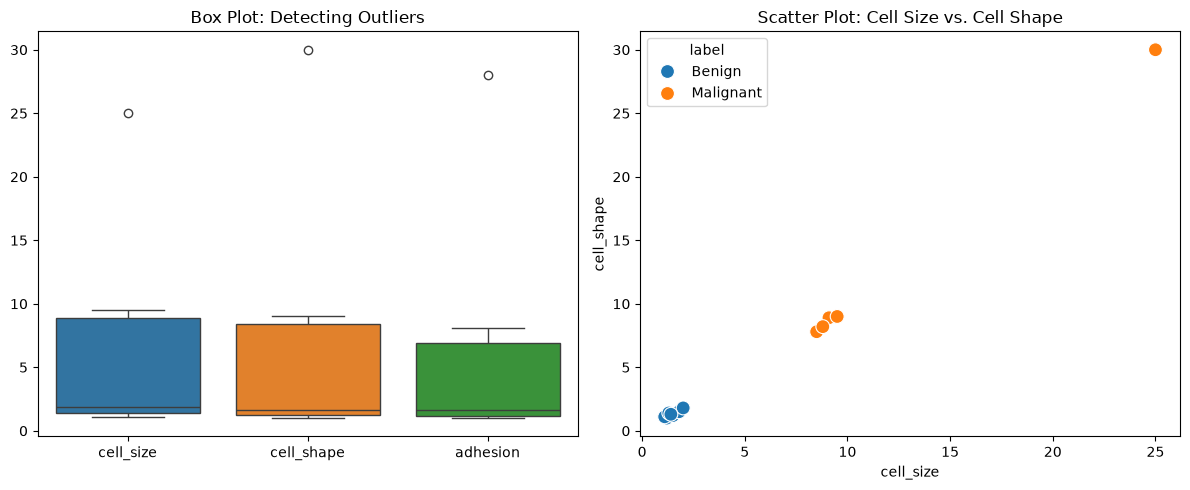

In [5]:
# ==========================================
# 3. DATA VISUALIZATION
# ==========================================
# Set up a subplot canvas
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Boxplot for Outlier Inspection
# Boxplot (sns.boxplot): Visually summarizes distributions while explicitly rendering points past whiskers as potential outliers.
sns.boxplot(ax=axes[0], data=df[["cell_size", "cell_shape", "adhesion"]])
axes[0].set_title("Box Plot: Detecting Outliers")

# Scatterplot for Feature Relationships
# Scatter Plot (sns.scatterplot): Maps two continuous variables along axes to uncover spatial clusters or visual correlations.
sns.scatterplot(
    ax=axes[1], data=df, x="cell_size", y="cell_shape", hue="label", s=100
)
axes[1].set_title("Scatter Plot: Cell Size vs. Cell Shape")

plt.tight_layout()
plt.show()

In [6]:
# ==========================================
# 4. PREPROCESSING & FEATURE SCALING
# ==========================================
# Drop target and metadata columns to isolate features
X = df[["cell_size", "cell_shape", "adhesion"]]
y = df["label"]

# Scale features so large values don't distort distance-based algorithms
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [7]:
# ==========================================
# 5. SUPERVISED LEARNING (Classification)
# ==========================================
# Split data into Training and Testing sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

# Train K-Nearest Neighbors Classifier
# Supervised Learning (K-Nearest Neighbors): Uses labeled historical data (y = label) to learn decision boundaries. 
# Unseen points are classified according to the majority class among their k-Nearest Neighbors
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

# Predictions & Evaluation
y_pred = knn.predict(X_test)
print("\n--- Supervised Learning (KNN Model Performance) ---")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


--- Supervised Learning (KNN Model Performance) ---
Accuracy: 1.0
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00         2
   Malignant       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



In [8]:
# ==========================================
# 6. UNSUPERVISED LEARNING (Clustering)
# ==========================================
# Apply K-Means Clustering (Group data into 2 clusters without using labels)
# Unsupervised Learning (K-Means Clustering): Group data points based entirely on feature proximity without accessing ground-truth labels. 
# It divides data into K distinct geometric clusters.
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
df["cluster_group"] = kmeans.fit_predict(X_scaled)

print("\n--- Unsupervised Learning (K-Means Cluster Assignments) ---")
print(df[["cell_size", "cell_shape", "cluster_group", "label"]])


--- Unsupervised Learning (K-Means Cluster Assignments) ---
    cell_size  cell_shape  cluster_group      label
0         1.2         1.0              0     Benign
1         1.5         1.2              0     Benign
2         1.8         1.5              0     Benign
3         1.1         1.1              0     Benign
4         1.3         1.4              0     Benign
5         2.0         1.8              0     Benign
6         8.5         7.8              0  Malignant
7         9.1         8.9              0  Malignant
8         8.8         8.2              0  Malignant
9         9.5         9.0              0  Malignant
10        1.4         1.3              0     Benign
11       25.0        30.0              1  Malignant
